<a href="https://colab.research.google.com/github/manasabt1997-max/Data-science/blob/main/CNN_TRAINING_AND_TESTING_THE_MODEL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Cell image classification using CNN



In [1]:
#step 1 import libraries
import tensorflow as tf
from keras import layers, models
import matplotlib.pyplot as plt
import numpy as np
print(tf.__version__)

2.21.0


In [ ]:
#step 2 load datasets
#we can use CIFAR-10 dataset as demo
#imagine cats= healthy cells, dogs= diseased cellls
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()
# nORMAALIZE IMAGES
X_train = X_train/255.0
X_test = X_test/255.0
print(X_train.shape)
print(X_test.shape)

 68009984/170498071 ━━━━━━━━━━━━━━━━━━━━ 16:38 10us/step

In [5]:
#step 3 select 2 clases for binary clasification
#example biological senario
#healthy vs diseased cells
selected_classes = [3, 5]
train_fitter = np.where((y_train == selected_classes[0]) | (y_train == selected_classes[1]))[0]
test_fitter = np.where((y_test == selected_classes[0]) | (y_test == selected_classes[1]))[0]
X_train = X_train[train_fitter]
y_train = y_train[train_fitter]
X_test = X_test[test_fitter]
y_test = y_test[test_fitter]

In [7]:
#convert label to binaries
y_train = (y_train == selected_classes[0]).astype(int)
y_test = (y_test == selected_classes[0]).astype(int)
print("Filtered training shape:", X_train.shape)

Filtered training shape: (10000, 32, 32, 3)


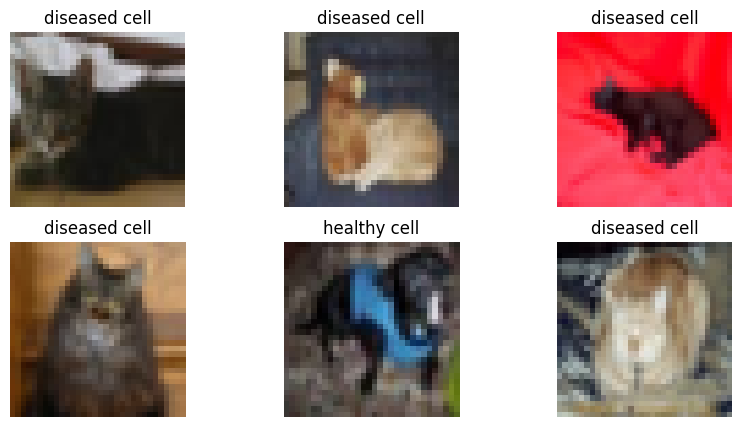

In [19]:
#step 4: display simple images
class_names = ['healthy cell', 'diseased cell']
plt.figure(figsize=(10, 5))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(X_train[i])
    plt.title(class_names[int(y_train[i][0])])
    plt.axis('off')
plt.show()

In [11]:
#step 5: Build CNN model
model = models.Sequential()
#convolution layer 1
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
model.add(layers.MaxPooling2D((2, 2)))
#convolution layer 2
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
model.add(layers.MaxPooling2D((2, 2)))
#convolution layer 3
model.add(layers.Conv2D(64, (3, 3), activation='relu'))
#flatten layer
model.add(layers.Flatten())
#dense layer
model.add(layers.Dense(64, activation='relu'))
#output layer
model.add(layers.Dense(1, activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [12]:
#step 6: compile model
model.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics = ['accuracy'])

In [20]:
#step 7
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 365,957 (1.40 MB)

 Trainable params: 121,985 (476.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 243,972 (953.02 KB)

In [15]:
#step 8: Train CNN model
history = model.fit(X_train, y_train, epochs = 5, validation_data = (X_test, y_test), batch_size = 32)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 17s 47ms/step - accuracy: 0.5778 - loss: 0.6696 - val_accuracy: 0.6365 - val_loss: 0.6479
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 45ms/step - accuracy: 0.6579 - loss: 0.6170 - val_accuracy: 0.6725 - val_loss: 0.6016
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 47ms/step - accuracy: 0.7015 - loss: 0.5655 - val_accuracy: 0.7200 - val_loss: 0.5445
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 21s 48ms/step - accuracy: 0.7278 - loss: 0.5349 - val_accuracy: 0.7300 - val_loss: 0.5314
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 46ms/step - accuracy: 0.7523 - loss: 0.4994 - val_accuracy: 0.7400 - val_loss: 0.5173


In [16]:
#step 9: evaluate model
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print(f"Test accuracy: {test_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.7400 - loss: 0.5173
Test accuracy: 0.7400000095367432


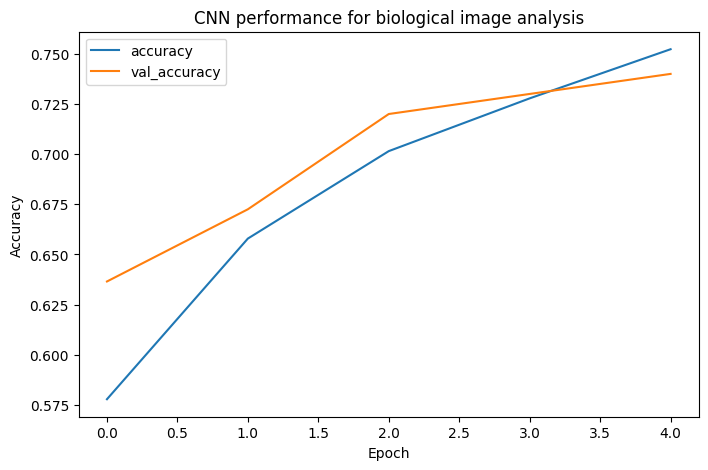

In [17]:
#step 10: plot accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('CNN performance for biological image analysis')
plt.legend()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 129ms/step


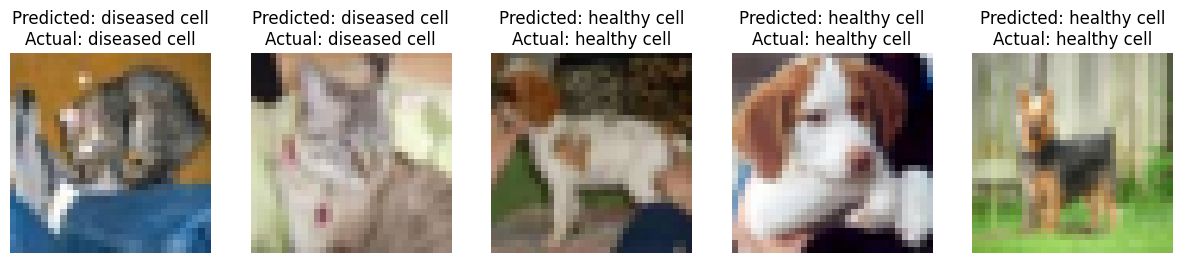

In [22]:
#step 11: prediction demo
preditions = model.predict(X_test[:5])
plt.figure(figsize=(15, 4))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_test[i])
    predicted_label = class_names[int(preditions[i][0] > 0.5)]
    actual_label = class_names[int(y_test[i][0])]
    plt.title(f"Predicted: {predicted_label}\nActual: {actual_label}")
    plt.axis('off')
plt.show()